# Tutorial 4 — Escoamento interno em um cano com canto

## 1. Importações

In [1]:
from pathlib import Path
import sys

# Importar o pacote local
project_root = Path.cwd()
if project_root.name == "tutorials":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

import numpy as np

from meshlab.core import Mesh, Curve, Contour, Front
from meshlab.operations import (
    insert_contour, initialize_front, compute_normals, advance_front,
    compute_angles, smooth_normals,
)
from meshlab.utils import plot_mesh

## 2. Parâmetros

In [2]:
num_layers = 4
height = 0.025
growth_rate = 1.10
points_per_segment = 21
smooth_steps = 5
relaxation = 1.0

## 3. Entrada, saída e paredes

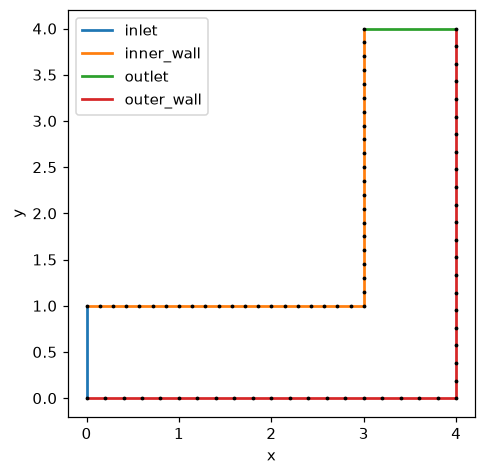

In [3]:
# Contorno horário: normais das paredes apontam para o fluido
inlet = Curve("inlet", [[0.0, 0.0], [0.0, 1.0]])

inner_points = np.vstack((
    np.linspace([0.0, 1.0], [3.0, 1.0], points_per_segment, endpoint=False),
    np.linspace([3.0, 1.0], [3.0, 4.0], points_per_segment),
))
inner_wall = Curve("inner_wall", inner_points)

outlet = Curve("outlet", [[3.0, 4.0], [4.0, 4.0]])

outer_points = np.vstack((
    np.linspace([4.0, 4.0], [4.0, 0.0], points_per_segment, endpoint=False),
    np.linspace([4.0, 0.0], [0.0, 0.0], points_per_segment),
))
outer_wall = Curve("outer_wall", outer_points)

channel = Contour("channel", [inlet, inner_wall, outlet, outer_wall])
mesh = Mesh(dim=2)
insert_contour(mesh, channel)

plot_mesh(mesh);

## 4. Frentes nas paredes

In [4]:
inner_front = Front("inner_front", int_dtype=mesh.int_dtype)
outer_front = Front("outer_front", int_dtype=mesh.int_dtype)

# Entrada e saída guiam os extremos; não geram camadas
initialize_front(mesh, inner_front, curves=["inner_wall"], guides=["inlet", "outlet"])
initialize_front(mesh, outer_front, curves=["outer_wall"], guides=["inlet", "outlet"])

## 5. Primeira camada

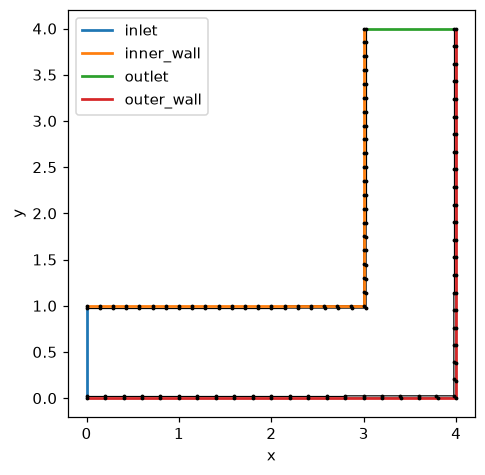

In [5]:
for front in [inner_front, outer_front]:
    normals = compute_normals(mesh, front, method="bisector")

    rotation = np.zeros(len(normals), dtype=mesh.float_dtype)
    for _ in range(smooth_steps):
        normals, step_rotation = smooth_normals(mesh, front, normals, relaxation)
        rotation += step_rotation

    angles = compute_angles(mesh, front)
    # Mesma correção de altura usada no t3
    heights = height / np.sin(angles / 2 + np.abs(rotation))
    advance_front(mesh, front, normals, heights)

plot_mesh(mesh);

## 6. Camadas restantes

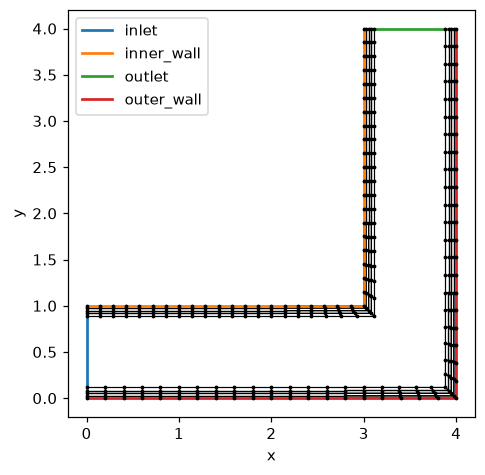

In [6]:
h = height
for _ in range(num_layers - 1):
    h *= growth_rate
    for front in [inner_front, outer_front]:
        normals = compute_normals(mesh, front, method="bisector")

        rotation = np.zeros(len(normals), dtype=mesh.float_dtype)
        for _ in range(smooth_steps):
            normals, step_rotation = smooth_normals(mesh, front, normals, relaxation)
            rotation += step_rotation

        angles = compute_angles(mesh, front)
        heights = h / np.sin(angles / 2 + np.abs(rotation))
        advance_front(mesh, front, normals, heights)

# A região central permanece sem preenchimento
plot_mesh(mesh);